In [25]:

import zipfile
import matplotlib.pyplot as plt

In [26]:
path =  zipfile.ZipFile("/content/road damage.v4i.yolo26.zip")

In [27]:
path.extractall("road_damage_detection")

In [28]:
pip install ultralytics

In [29]:
from ultralytics import YOLO

In [30]:
model = YOLO("yolo26l.pt")

In [31]:
pred = model.predict("/content/CR-Cars-Inline-2027-Audi-SQ9-f-static-7-26.webp")


image 1/1 /content/CR-Cars-Inline-2027-Audi-SQ9-f-static-7-26.webp: 352x640 1 car, 47.1ms
Speed: 2.5ms preprocess, 47.1ms inference, 3.0ms postprocess per image at shape (1, 3, 352, 640)


array([[[154, 166, 200],
        [154, 166, 200],
        [154, 166, 200],
        ...,
        [178, 170, 194],
        [178, 170, 194],
        [178, 170, 194]],

       [[154, 166, 200],
        [154, 166, 200],
        [154, 166, 200],
        ...,
        [178, 170, 194],
        [178, 170, 194],
        [178, 170, 194]],

       [[154, 166, 200],
        [154, 166, 200],
        [154, 166, 200],
        ...,
        [178, 170, 194],
        [178, 170, 194],
        [178, 170, 194]],

       ...,

       [[ 40,  38,  38],
        [ 40,  38,  38],
        [ 40,  38,  38],
        ...,
        [ 38,  36,  36],
        [ 38,  36,  36],
        [ 38,  36,  36]],

       [[ 39,  37,  37],
        [ 39,  37,  37],
        [ 39,  37,  37],
        ...,
        [ 37,  35,  35],
        [ 37,  35,  35],
        [ 37,  35,  35]],

       [[ 38,  36,  36],
        [ 38,  36,  36],
        [ 39,  37,  37],
        ...,
        [ 37,  35,  35],
        [ 37,  35,  35],
        [ 37,  35,  35]]], dtype=uint8)
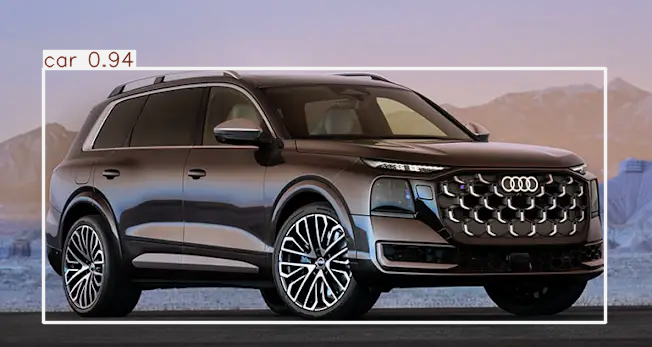

In [32]:
pred[0].plot()

In [33]:
model.train(data="/content/road_damage_detection/data.yaml",epochs = 10,batch = 32)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/road_damage_detection/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=F

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x789dc6e62350>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

In [34]:
results = model.val()

print("Precision:", results.box.mp)
print("Recall:", results.box.mr)
print("mAP50:", results.box.map50)
print("mAP50-95:", results.box.map)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l summary (fused): 188 layers, 24,748,053 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1689.0±513.4 MB/s, size: 75.6 KB)
val: Scanning /content/road_damage_detection/valid/labels.cache... 330 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 330/330 92.3Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 378, len(boxes) = 386. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 1.2it/s 17.6s
                   all        330        386       0.65      0.688      0.651      0.416
                 Bagus        124        124      0.971          1      0.973      0.794
                 Parah 

In [40]:
model.predict("/content/700_F_442740822_7s8p55nauSEe3as49CUKZISBPF2hTL1s_ST.mp4",save = True)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/526) /content/700_F_442740822_7s8p55nauSEe3as49CUKZISBPF2hTL1s_ST.mp4: 384x640 1 Parah, 45.5ms
video 1/1 (frame 2/526) /content/700_F_442740822_7s8p55nauSEe3as49CUKZISBPF2hTL1s_ST.mp4: 384x640 1 Parah, 45.6ms
video 1/1 (frame 3/526) /content/700_F_442740822_7s8p55nauSEe3as49CUKZISBPF2hTL1s_ST.mp4: 384x640 1 Parah, 34.2ms
video 1/1 (frame 4/526) /content/700_F_442740822_7s8p55nauSEe3as49CUKZISBPF2hTL1s_ST.mp4: 384x640 1 Parah, 37.0ms
vid

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'Bagus', 1: 'Parah', 2: 'Sedang'}
 obb: None
 orig_img: array([[[ 48,  48,  48],
         [ 48,  48,  48],
         [ 47,  47,  47],
         ...,
         [ 63,  70,  75],
         [ 60,  70,  74],
         [ 46,  56,  60]],
 
        [[ 48,  48,  48],
         [ 48,  48,  48],
         [ 47,  47,  47],
         ...,
         [ 59,  66,  71],
         [ 60,  70,  74],
         [ 50,  60,  64]],
 
        [[ 48,  48,  48],
         [ 48,  48,  48],
         [ 47,  47,  47],
         ...,
         [ 72,  79,  84],
         [ 77,  87,  91],
         [ 79,  89,  93]],
 
        ...,
 
        [[127, 145, 155],
         [129, 147, 157],
         [127, 145, 155],
         ...,
         [105, 117, 116],
         [113, 125, 124],
         [120, 132, 131]],
 
        [[ 97, 111, 124],
         [ 77,  91, 104],
         [ 83, 103, 1

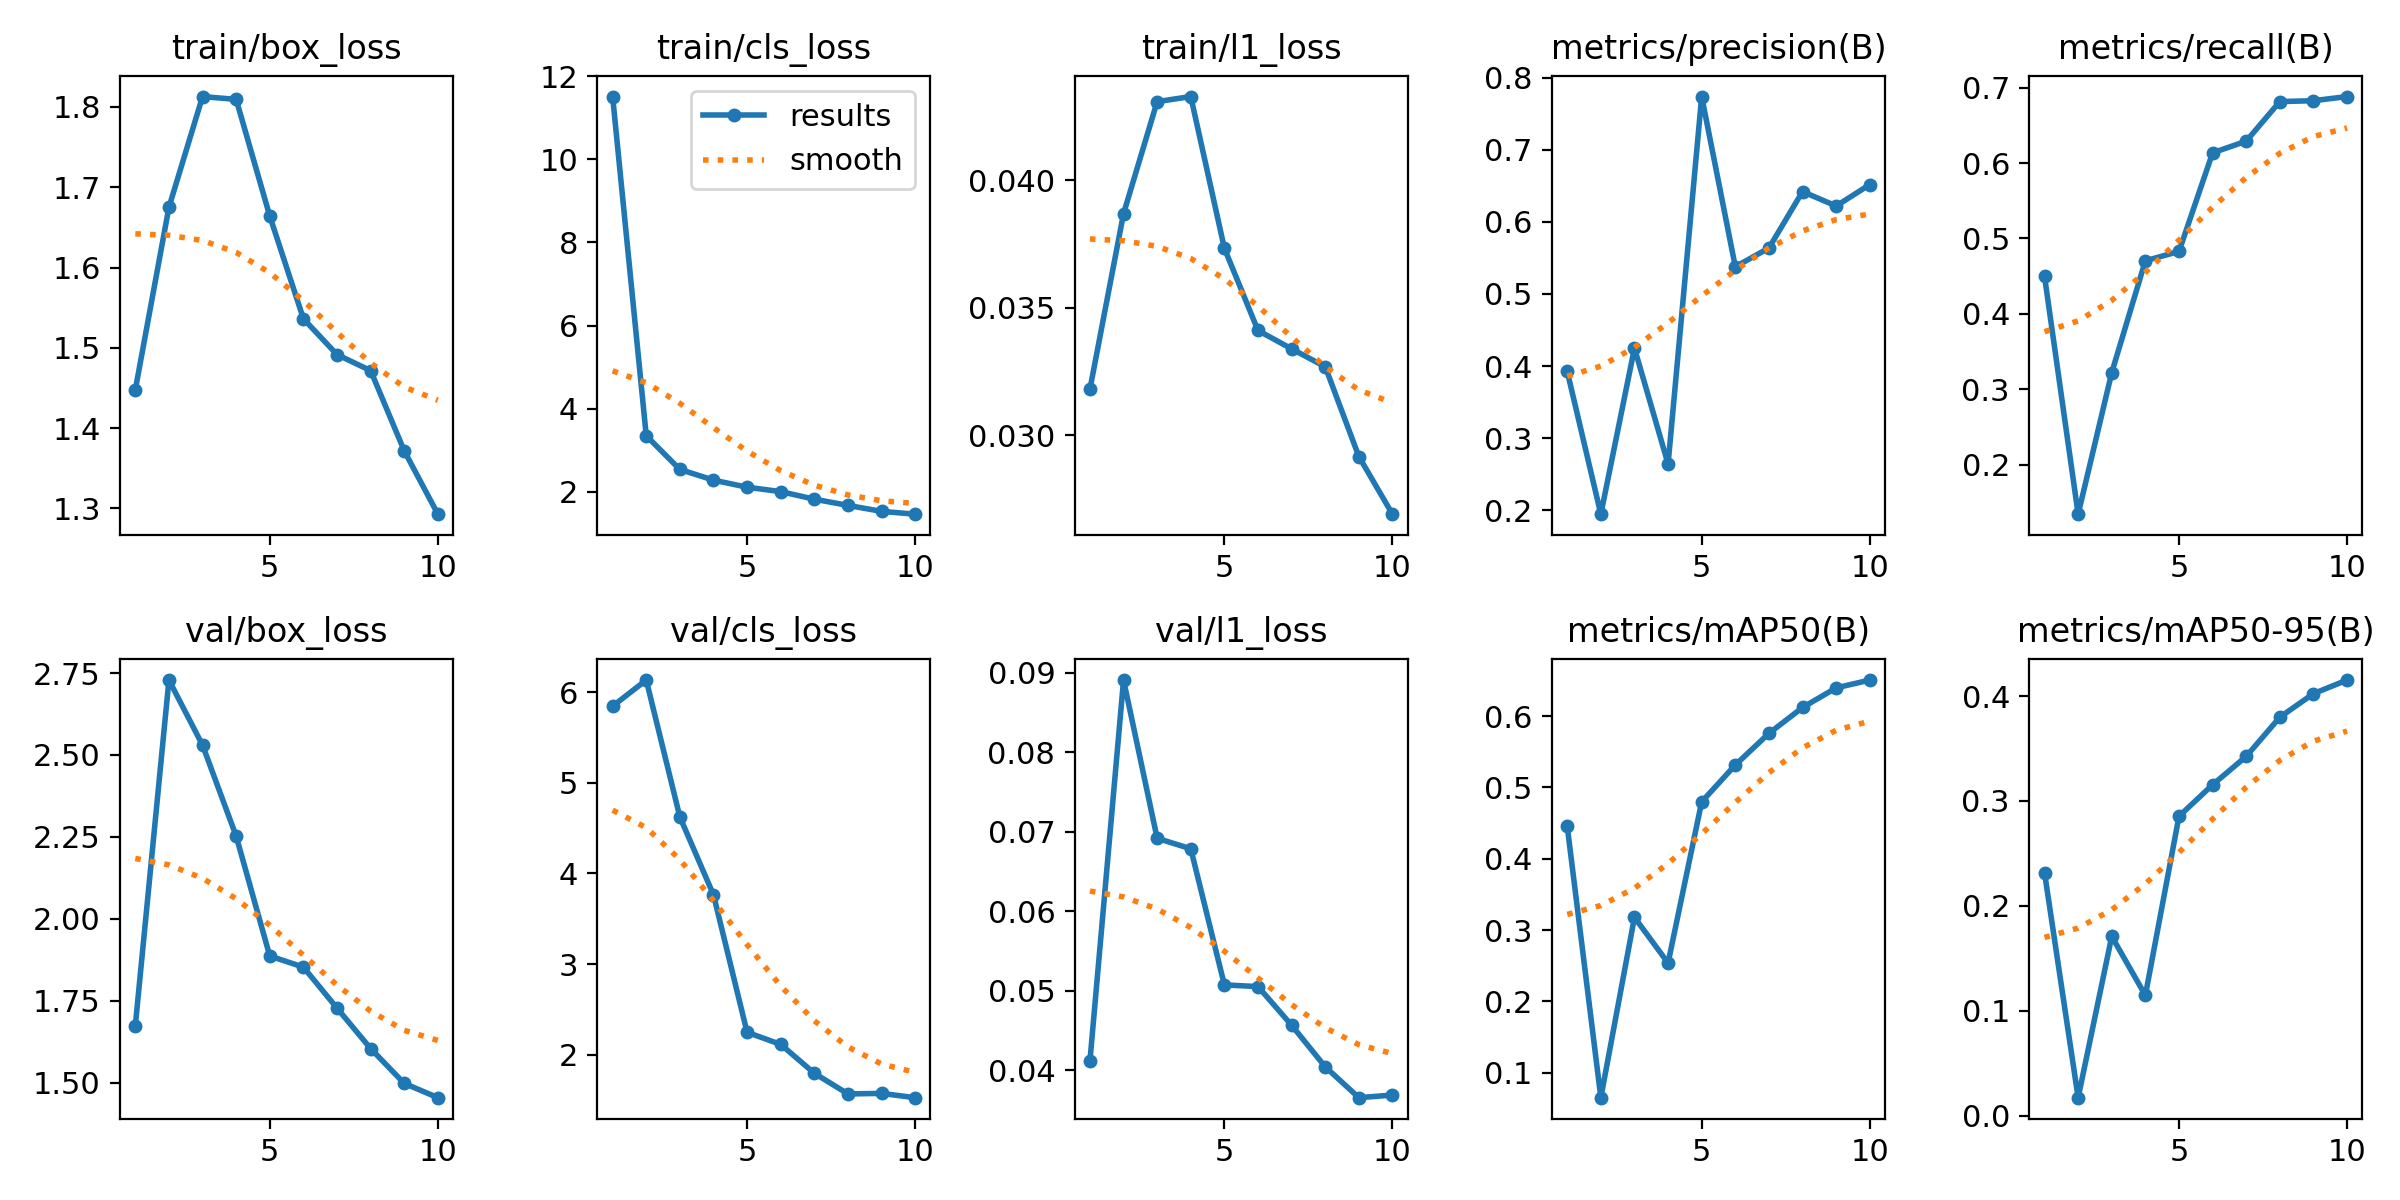

In [35]:
from IPython.display import Image, display

display(Image("runs/detect/train/results.png"))

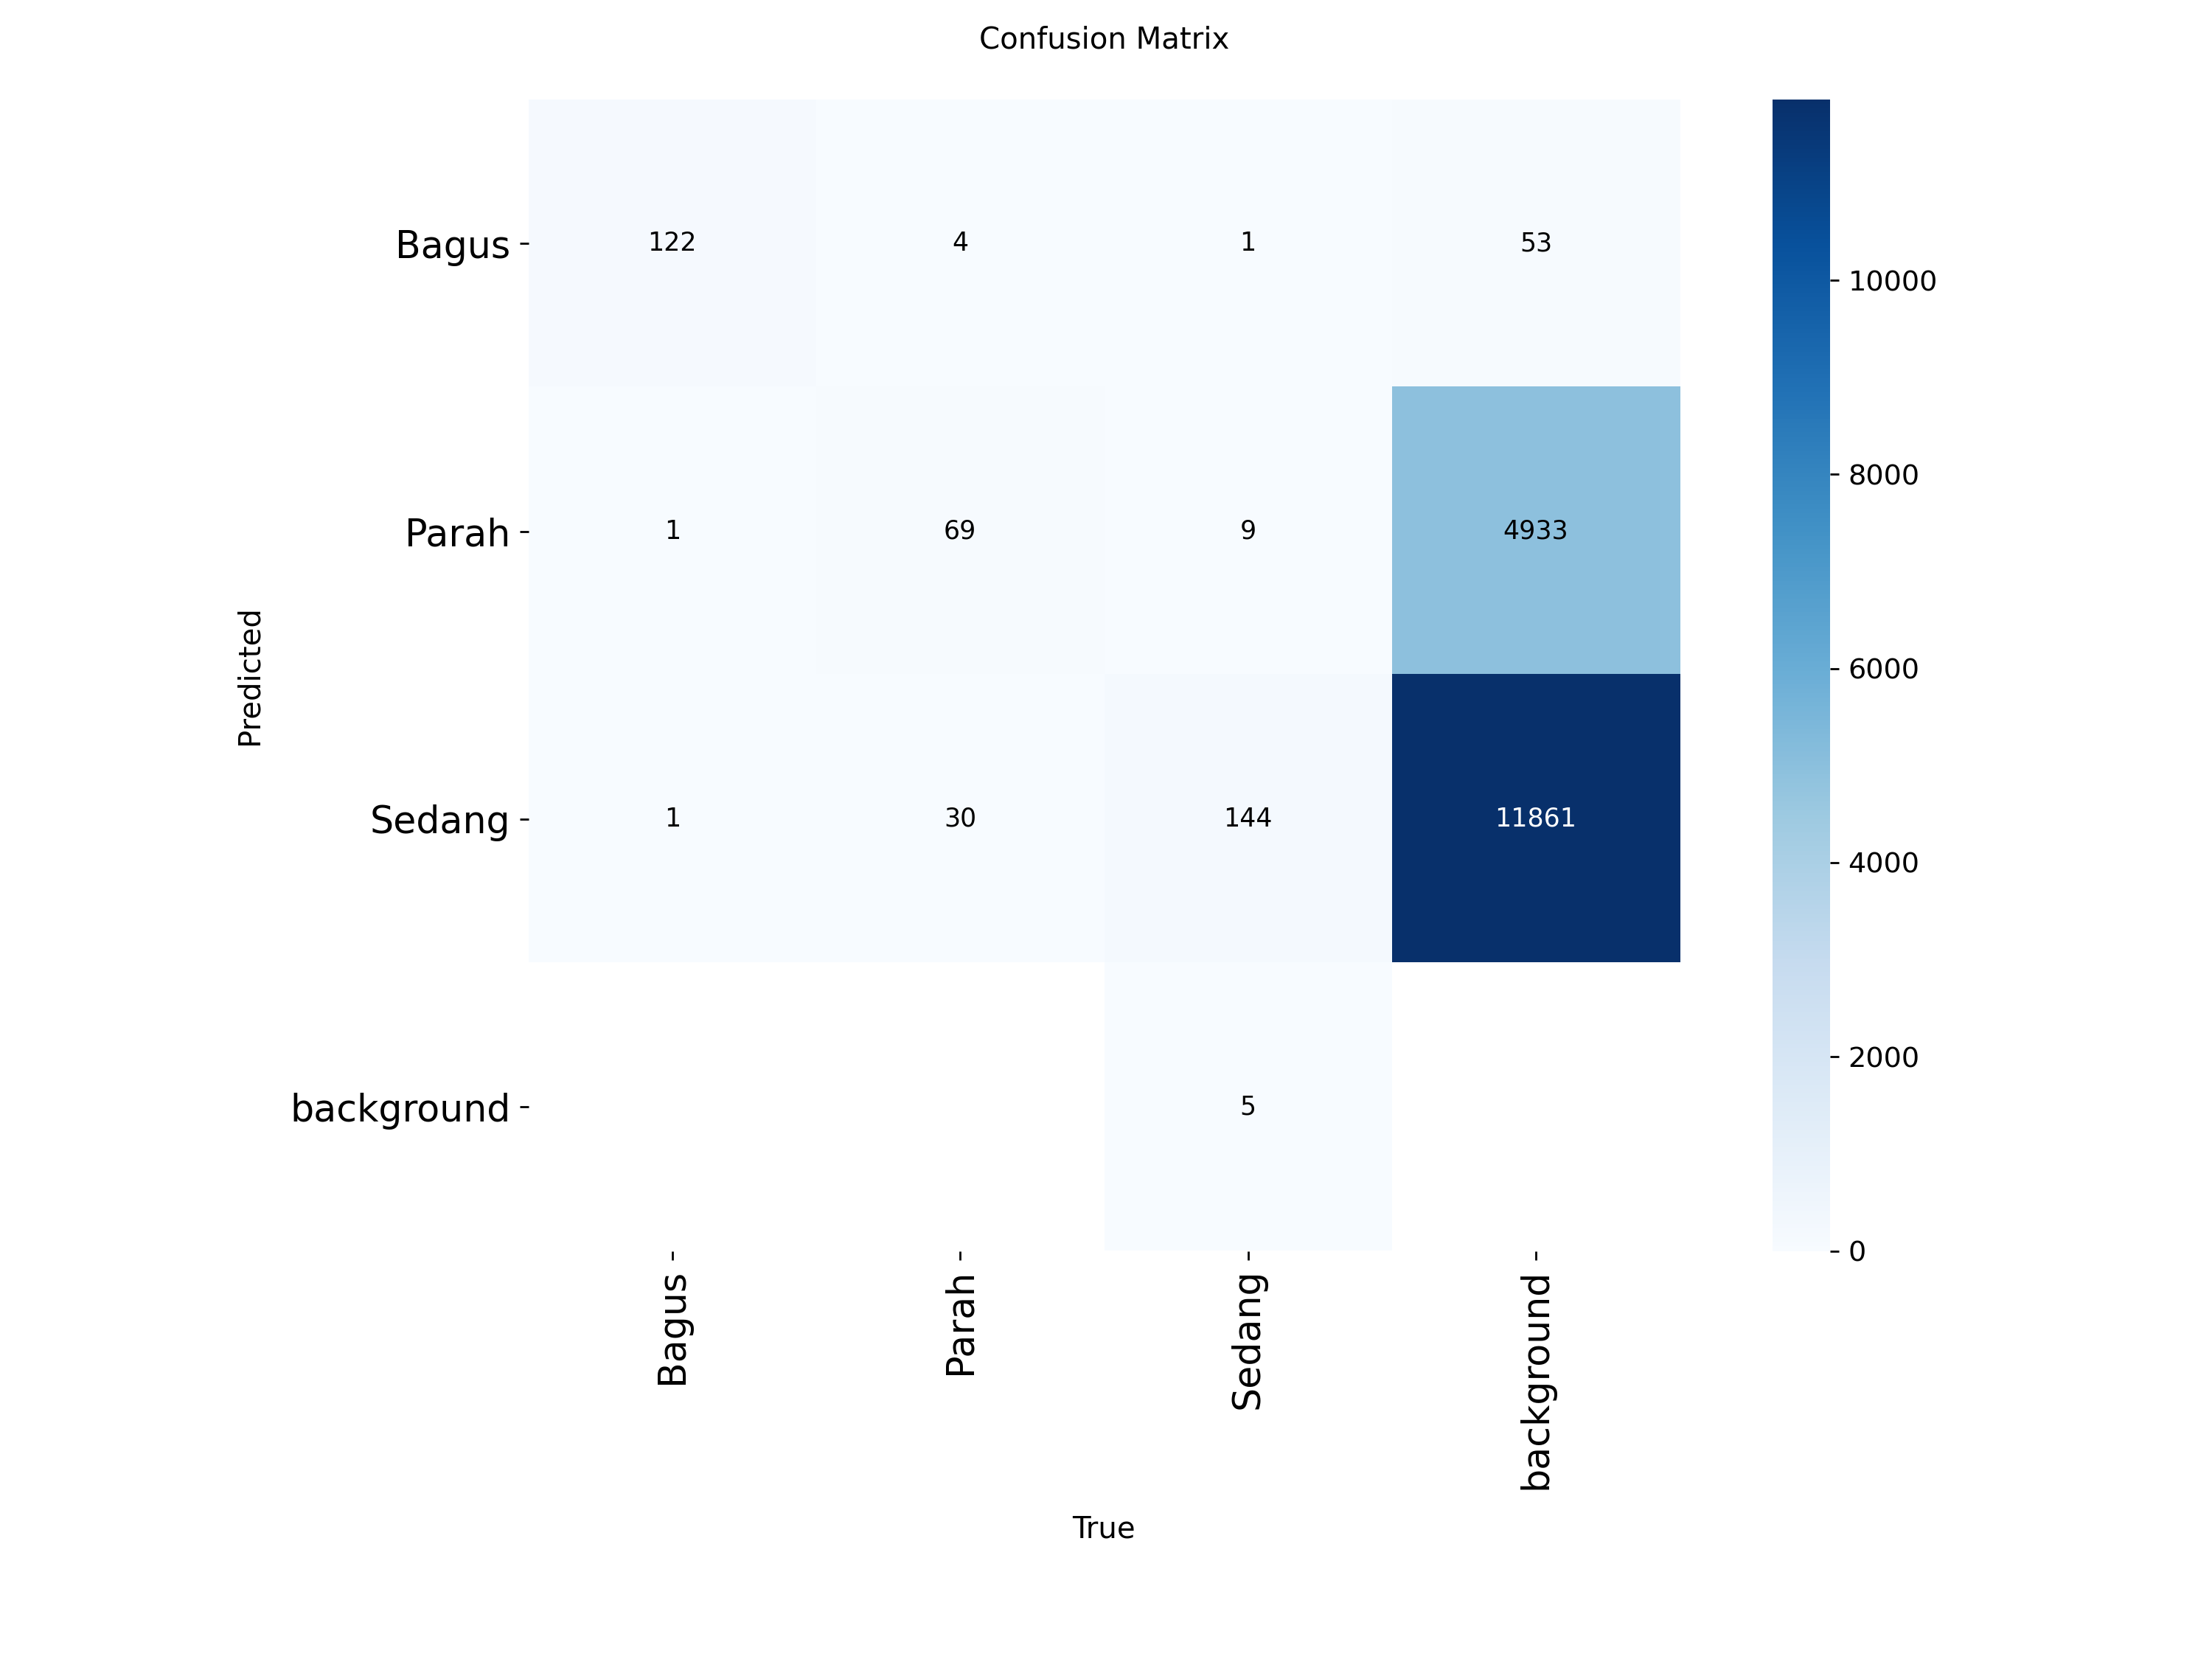

In [36]:
display(Image("runs/detect/train/confusion_matrix.png"))

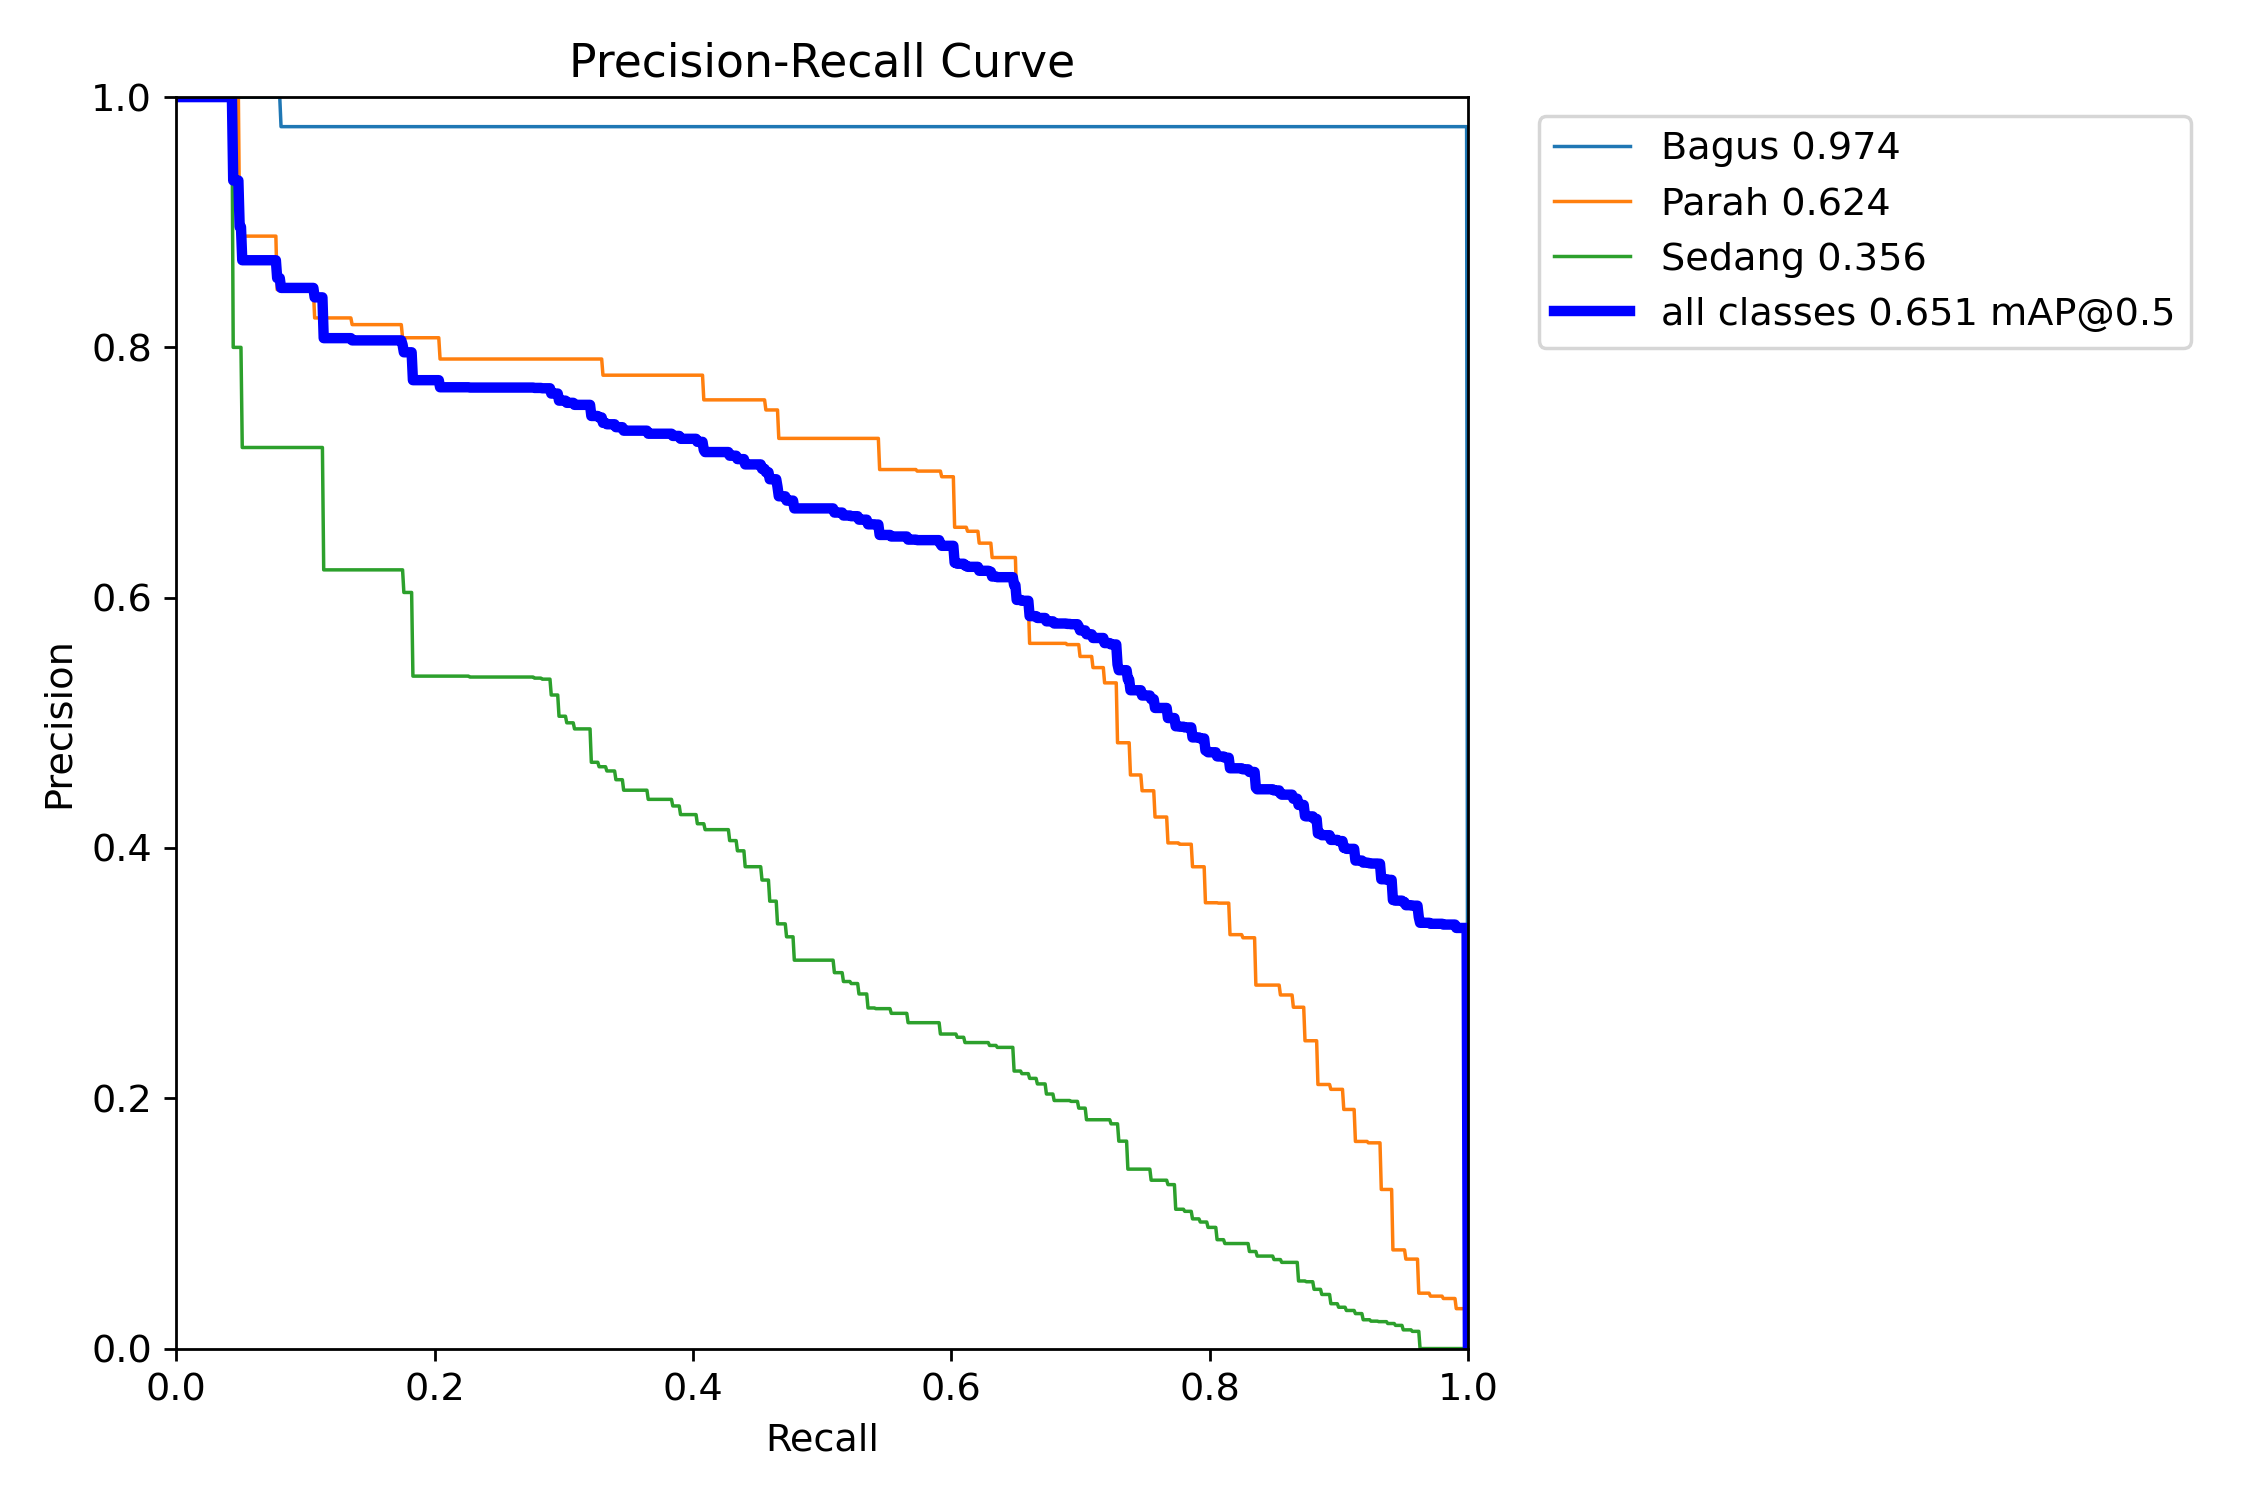

In [37]:
display(Image("runs/detect/train/BoxPR_curve.png"))

In [38]:
import gradio as gr

model = YOLO("runs/detect/train/weights/best.pt")

def detect(img):
    return model(img)[0].plot()

gr.Interface(
    fn=detect,
    inputs=gr.Image(type="numpy"),
    outputs=gr.Image(),
    title="🚗 Road Damage Detection",
    theme=gr.themes.Soft()
).launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dcb51a3a099ebc18c1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
